# K-Nearest Neighbours (KNN) from scratch

This notebook is a guide on building a KNN using a bit of Python. KNNs are K nearest neighbours (which we talked about in the lecture). 

The overview of KNNs in case you do not remember, is to guess what a new datapoint is, we find the **k** things we already know that are the closest to this new point, and let this vote. 

# Step 1: imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Step 2: dataset

To demonstrate K-Nearest Neighbours, we will use a dataset of fruits.

Each fruit has two features:
- **size**
- **sweetness**

Each fruit also has a label.

In [3]:
X = np.array([
    [5.0, 2.0], [5.5, 3.0], [6.0, 2.5], [4.5, 1.5], [6.5, 3.5],   # lemons
    [7.0, 7.0], [7.5, 8.0], [8.0, 6.5], [6.5, 7.5], [8.5, 8.5],   # apples
])

y = np.array([0,0,0,0,0,1,1,1,1,1]) # To show which one is lemon or apple
names = ["lemon", "apple"]

We can plot these points on a graph of size against sweetness. You will recognise this from what we did in the lecture once we plot this.

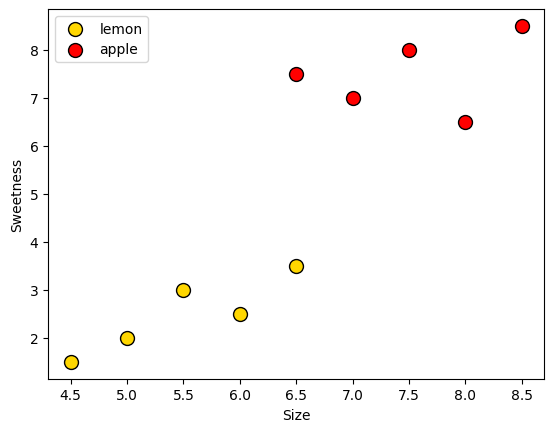

In [5]:
# This is just for visualisation, not necessary.

colours = ["gold", "red"]
for i in range(2):
    plt.scatter(X[y == i, 0], X[y == i, 1], c=colours[i], s=100, edgecolors="k", label=names[i])

plt.xlabel("Size")
plt.ylabel("Sweetness")
plt.legend()
plt.show()

# Step 3: Measuring distance

If we recall the lecture, we talked about the main method for measuring distance for KNNs - Pythagoras. There was another way we talked about (Manhattan distance), however here we use Euclidean distance.

In [6]:
def distance(a, b): # function to measure distance between point a and b
    return np.sqrt(np.sum((a-b)**2)) # just pythagoras

# Step 4: New fruit

Someone gives us a fruit 6.8 cm big with sweetness 6. How would the model classify this?

First we need to work out how far it is from every fruit we already know, using the distance function we defined.

In [7]:
new = np.array([6.8, 6.0])

distances = [distance(new, j) for j in X] # Find distances between new fruit and all the others.

# Step 5: Find the k nearest neighbours

Let us set k = 3. This means we want to find the 3 nearest neighbours.

We can use np.argsort to give us the positions of the distances, sorted from smallest to largest.

In [8]:
k = 3

nearest = np.argsort(distances)[:k]

# Step 6: Voting

In [9]:
votes = Counter(y[nearest]) # Here Counter() outputs count for each fruit (votes)

winner = votes.most_common(1)[0][0]

print("Winner:", names[winner])

Winner: apple


Steps 3-5 together is the KNN algorithm. Let's now see the decision boundary for the KNN (The line where colour changes).

In [15]:
# Full algorithm:

def knn_predict(new, X, y, k=3):
    distances = [distance(new, point) for point in X]  
    nearest = np.argsort(distances)[:k]                      
    votes = Counter(y[nearest])                              
    return votes.most_common(1)[0][0]                        

print(names[knn_predict(np.array([6.8, 6.0]), X, y, k=3)])
print(names[knn_predict(np.array([5.0, 3.0]), X, y, k=3)])

apple
lemon


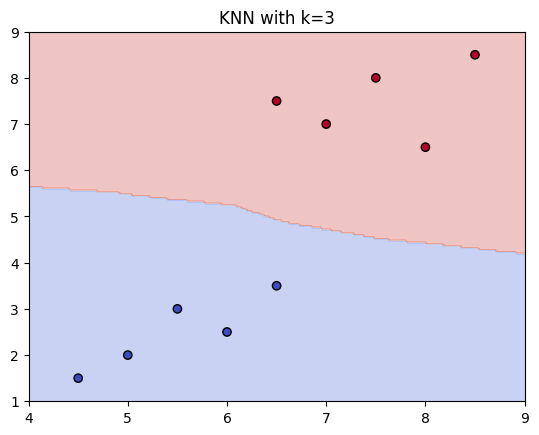

In [ ]:
# This code plots the decision boundary. This is just for visualisation.

def plot_decision_boundary(predict_fn, X, y, title=""):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = np.array(predict_fn(grid)).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
    plt.title(title)
    plt.show()

def predict_many(points, k=3):
    return [knn_predict(p, X, y, k) for p in points]

plot_decision_boundary(lambda pts: predict_many(pts, k=3), X, y, title="KNN with k=3")